In [6]:
import math
from functools import reduce
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from matplotlib.lines import Line2D

In [7]:
def CollectXY(Vecs):
    def build(pair, vec):
        (xs, ys) = pair
        [x, y] = vec
        return (xs + [x], ys + [y])
    return np.array(reduce(build, Vecs, ([], [])))

def Center(list):
    N=len(list)
    arr=np.array(list)
    return reduce(lambda v,x: v+x, arr,0)/N

def Project4Dto2D(Vec):
    x,y,z, t=Vec
    return x/(z*t), y/(z*t)

def MatrixProj4D(Vec):
    R=[]
    for i in Vec:
        R=R+[Project4Dto2D(i)]
    return R

def Project3Dto2D(Vec):
    x,y,z=Vec
    return x/z, y/z

def MatrixProj3D(Vec):
    R=[]
    for i in Vec:
        R=R+[Project3Dto2D(i)]
    return R

In [8]:
class Rectangle:
    def __init__(self, Vec):
        self.Vec=np.array(Vec)
    def get_Center(self):
        return Center(self.Vec)
    def get_Lines(self):
        A,B,C,D=self.Vec
        if len(A)==2:
            return CollectXY([A,B,C,D,A])
        if len(A)==3:
            return CollectXY(MatrixProj3D([A,B,C,D,A]))
        if len(A)==4:
            return CollectXY(MatrixProj4D([A,B,C,D,A]))
    def proj_4D(self):
        x,y,z,t = self.Vec
        if t*z != 0:
            return x/(z*t), y/(z*t)
    def get_Corners(self):
        A,B,C,D=self.Vec
        return A,B,C,D
    def move(self, vector):
        self.Vec=self.Vec +np.array(vector)
        
    def rotate(self, alpha, a,b):
        Vec1 = np.array(self.get_Center())
        self.move(-Vec1)
        i=0
        x=0
        y=0
        while i<4:
            x,y = self.Vec[i][a] , self.Vec[i][b]
            self.Vec[i][a] , self.Vec[i][b] = x*math.cos(alpha)+y*math.sin(alpha), -x*math.sin(alpha)+y*math.cos(alpha)
            i += 1
        self.move(Vec1)
        
        
    def rotateAround(self, alpha, a,b, V):
        self.move(-V)
        i=0
        while i<4:
            x,y = self.Vec[i][a] , self.Vec[i][b]
            self.Vec[i][a] , self.Vec[i][b] = x*math.cos(alpha)-y*math.sin(alpha), x*math.sin(alpha)+y*math.cos(alpha)
            i += 1
        self.move(V)
        
    def set_Coord(self,vec):
        self.Vec=np.array(vec)
        
    
class Cube:
    def __init__(self, Rectangle1, Rectangle2):
        self.Rec1=Rectangle1
        self.Rec2=Rectangle2
    def get_Center(self):
        return Center(self.get_Corners())
    def get_Lines(self):
        Result=[]
        A=self.Rec1.get_Corners()
        B=self.Rec2.get_Corners()
        i=0
        if len(A[0])==3:
            while i<len(A):
                Result=Result+[CollectXY(MatrixProj3D([A[i],B[i]]))]
                i=i+1
        if len(A[0])==4:
            while i<len(A):
                Result=Result+[CollectXY(MatrixProj4D([A[i],B[i]]))]
                i=i+1
        Result=Result+[self.Rec1.get_Lines()]+[self.Rec2.get_Lines()]
        return Result
    def get_Corners(self):
        A=self.Rec1.get_Corners()
        B=self.Rec2.get_Corners()
        return A+B
    
    def move(self, vector):
        self.Rec1.move(vector)
        self.Rec2.move(vector)
        
    def rotate(self, alpha, a,b):
        C=self.get_Center()
        self.Rec1.rotateAround(alpha, a,b,np.array(C))
        self.Rec2.rotateAround(alpha, a,b,np.array(C))

        
    def rotateAround(self, alpha, a,b, V):
        self.Rec1.rotateAround(alpha, a,b,V)
        self.Rec2.rotateAround(alpha, a,b,V)
        
        
    def set_Coord(self,Rect1, Rect2):
        self.Rec1.set_Coord(Rect1)
        self.Rec2.set_Coord(Rect2)

    
class HyperCube:
    def __init__(self, Cube1, Cube2):
        self.Cube1=Cube1
        self.Cube2=Cube2
    def get_Center(self):
        return Center(self.get_Corners())
    def get_Lines(self):
        Result=[]
        A=self.Cube1.get_Corners()
        B=self.Cube2.get_Corners()
        i=0
        while i<len(A):
            Result=Result+[CollectXY(MatrixProj4D([A[i],B[i]]))]
            i=i+1
        Result=Result+self.Cube1.get_Lines()+self.Cube2.get_Lines()
        return Result
    def get_Corners(self):
        A=self.Cube1.get_Corners()
        B=self.Cube2.get_Corners()
        return A+B
    
    def move(self, vector):
        self.Cube1.move(vector)
        self.Cube2.move(vector)
        
        
    def rotate(self, alpha, a,b):
        C=self.get_Center()
        self.Cube1.rotateAround(alpha, a,b,np.array(C))
        self.Cube2.rotateAround(alpha, a,b,np.array(C))
        
    def set_Coord(self,Cu1, Cu2):
        A,B=Cu1
        C,D=Cu2
        self.Cube1.set_Coord(A,B)
        self.Cube2.set_Coord(C,D)



In [9]:
Rektangel0= Rectangle([[0.,0.], [0.,1.], [1.,1.], [1,0.]])
Rek1 = Rectangle([[-1,-1,3], [-1,1,3], [1,1,3], [1,-1,3]])
Rek2 = Rectangle([[-1,-1,5], [-1,1,5], [1,1,5], [1,-1,5]])
CubeR=Cube(Rek1, Rek2)
Rektangel1 = Rectangle([[-1,-1,3,3], [-1,1,3,3], [1,1,3,3], [1,-1,3,3]])
Rektangel2 = Rectangle([[-1,-1,5,3], [-1,1,5,3], [1,1,5,3], [1,-1,5,3]])
Rektangel3 = Rectangle([[-1,-1,3,5], [-1,1,3,5], [1,1,3,5], [1,-1,3,5]])
Rektangel4 = Rectangle([[-1,-1,5,5], [-1,1,5,5], [1,1,5,5], [1,-1,5,5]])

Cube1=Cube(Rektangel1, Rektangel2)
Cube2=Cube(Rektangel3, Rektangel4)
HyperCube1=HyperCube(Cube1,Cube2)

interactive(children=(FloatSlider(value=0.0, description='x', max=2.0, min=-2.0), FloatSlider(value=0.0, descr…

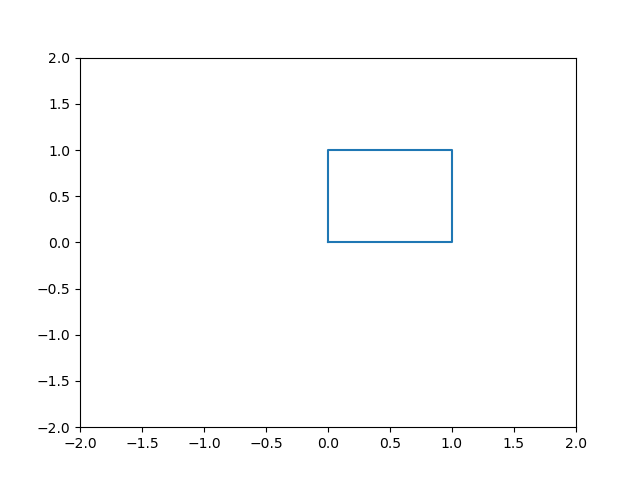

In [10]:
%matplotlib ipympl

fig, ax = plt.subplots()

Rektangel0= Rectangle([[0.,0.], [0.,1.], [1.,1.], [1,0.]])
    
@widgets.interact(x=(-2.0, 2.0), y=(-2.0,2.0), z=(-2.0,2.0),
                  alpha=(-2*math.pi, 2*math.pi))
def g(x,y, alpha):
    ax.clear()
    ax.set_xlim(-2,2)
    ax.set_ylim(-2,2)
    Rektangel0.set_Coord([[0.,0.], [0.,1.], [1.,1.], [1,0.]])
    Rektangel0.rotate(alpha,0,1)
    Rektangel0.move([x,y])
    A=Rektangel0.get_Lines()
    line=Line2D(A[0], A[1])
    ax.add_line(line)

    fig.canvas.draw_idle()

interactive(children=(FloatSlider(value=0.0, description='x', max=2.0, min=-2.0), FloatSlider(value=0.0, descr…

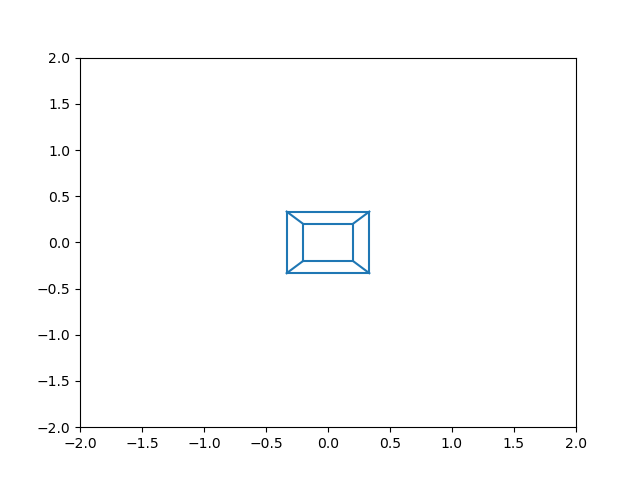

In [11]:
%matplotlib ipympl

fig, ax = plt.subplots()


Rek1 = Rectangle([[-1.,-1.,3.], [-1.,1.,3.], [1.,1.,3.], [1.,-1.,3.]])
Rek2 = Rectangle([[-1.,-1.,5.], [-1.,1.,5.], [1.,1.,5.], [1.,-1.,5.]])
CubeR=Cube(Rek1, Rek2)
    
@widgets.interact(x=(-2.0, 2.0), y=(-2.0,2.0), z=(-2.0,2.0),
                  alpha=(-2*math.pi, 2*math.pi), beta=(-2*math.pi, 2*math.pi),
                  gamma=(-2*math.pi, 2*math.pi))
def g(x,y,z, alpha, beta,gamma):
    ax.clear()
    ax.set_xlim(-2,2)
    ax.set_ylim(-2,2)
    CubeR.set_Coord([[-1.,-1.,3.], [-1.,1.,3.], [1.,1.,3.], [1.,-1.,3.]],
                    [[-1.,-1.,5.], [-1.,1.,5.], [1.,1.,5.], [1.,-1.,5.]]
                    )
    CubeR.rotate(alpha,0,1)
    CubeR.rotate(beta, 0,2)
    CubeR.rotate(gamma,1,2)
    CubeR.move([x,y,z])
    
    for i in CubeR.get_Lines():
        line=Line2D(i[0], i[1])
        ax.add_line(line)
    
    
    fig.canvas.draw_idle()

interactive(children=(FloatSlider(value=0.0, description='x', max=2.0, min=-2.0), FloatSlider(value=0.0, descr…

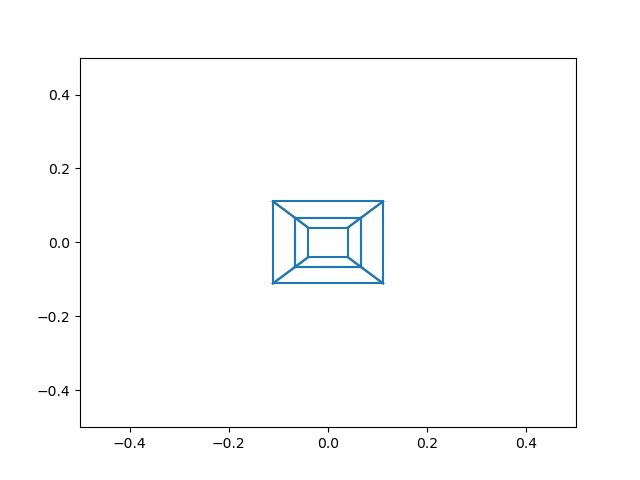

In [12]:
%matplotlib ipympl

fig, ax = plt.subplots()


for i in HyperCube1.get_Lines():
    ax.plot(i[0],i[1])[0]
    
@widgets.interact(x=(-2.0, 2.0), y=(-2.0,2.0), z=(-2.0,2.0), u=(-2.0,2.0),
                  alpha=(-2*math.pi, 2*math.pi), beta=(-2*math.pi, 2*math.pi),
                  gamma=(-2*math.pi, 2*math.pi), delta=(-2*math.pi, 2*math.pi), 
                  epsilon=(-2*math.pi, 2*math.pi), zeta=(-2*math.pi, 2*math.pi))
def g(x,y,z, u, alpha, beta, gamma,delta):
    ax.clear()
    ax.set_xlim(-0.5,0.5)
    ax.set_ylim(-0.5,0.5)
    HyperCube1.set_Coord([[[-1,-1,3,3], [-1,1,3,3], [1,1,3,3], [1,-1,3,3]],
                    [[-1,-1,5,3], [-1,1,5,3], [1,1,5,3], [1,-1,5,3]]],
                    [[[-1,-1,3,5], [-1,1,3,5], [1,1,3,5], [1,-1,3,5]],
                    [[-1,-1,5,5], [-1,1,5,5], [1,1,5,5], [1,-1,5,5]]]
                    )
    HyperCube1.rotate(alpha,1,0)
    HyperCube1.rotate(beta,2,0)
    HyperCube1.rotate(gamma,2,3)
    HyperCube1.rotate(delta,1,3)
    HyperCube1.move([x,y,z,u]) 
    for i in HyperCube1.get_Lines():
        line=Line2D(i[0], i[1])
        ax.add_line(line)
    
    
    fig.canvas.draw_idle()